# Configuration

In [1]:
# file_name = 'FullSailUniversity.mp3'
# speakers_expected = 7
# file_name = '2025 Q2 Group 1 Meet 1 - Jon Smith.m4a'
# speakers_expected = 7 # Actual value=7
# file_name = '2025 Q2 Group 1 Meet 2 - Mel Reyes.m4a'
# speakers_expected = 6
# file_name = 'GMT20250508-161006_Recording.mp4'
# speakers_expected = 2
# file_name = '2025 Q2 Group 1 Meet 3 - Zoe Kon.m4a'
# speakers_expected = 5
# file_name = 'Debate_Trump_Biden_2024.mp3'
# speakers_expected = 4
file_name = '2025 Q2 Group 1 Meet 4 - Brandy Ford.m4a'
speakers_expected = 5

In [2]:
# Jupyter stuff
# See https://ipython.org/ipython-doc/3/config/extensions/autoreload.html
%load_ext autoreload
%autoreload 2

# Actual config
import logging
import os
from pathlib import Path, PurePath

from dotenv import load_dotenv
from lib.config_functions import *

load_dotenv()  # Load environment variables

path_base = Path.cwd()
path_media = Path(path_base).joinpath('media')
path_output = Path(path_base).joinpath('output')
path_report_assets = Path(path_base).joinpath('report_assets')
path_prompt_templates = Path(path_base).joinpath('prompt_templates')
path_file = Path(path_media).joinpath(file_name)

# Create the working dir for the given file
_file_name_noext = PurePath(path_file).stem  # Remove the extension if any
path_work_dir = Path(path_output).joinpath(_file_name_noext)
path_work_dir.mkdir(exist_ok=True)

# Create assemblyai dir
path_transcript_dir = path_work_dir.joinpath('assemblyai_transcript')
path_transcript_dir.mkdir(exist_ok=True)

# Create report dir
path_reports_dir = path_work_dir.joinpath('reports')
path_reports_dir.mkdir(exist_ok=True)

# Configure logger
logger = logging.getLogger('root')
logger.handlers = []  # To allow to run this cell multiple times without creating more loggers
logger_add_handlers_file_stream(
    logger=logger, level=logging.DEBUG, filename=str(path_work_dir.joinpath('log.txt'))
)

# Obtaining audio transcript

In [3]:
import lib.assemblyai_helper_functions as ahf

path_response_upload_json = path_transcript_dir.joinpath('response_upload.json')
path_response_create_json = path_transcript_dir.joinpath('response_create.json')
path_response_transcript_json = path_transcript_dir.joinpath('response_transcript.json')
print(path_response_transcript_json)

transcript = ahf.get_audio_transcript(
    path_file,
    path_response_upload_json=path_response_upload_json,
    path_response_create_json=path_response_create_json,
    path_response_transcript_json=path_response_transcript_json,
    speakers_expected=speakers_expected,
    force_upload=False,
    force_regen=False,
)

INFO:root:assemblyai_helper_functions.py(177):get_audio_transcript 2025-05-19 21:26:02,067
Creating Audio transcript
INFO:root:assemblyai_helper_functions.py(30):_upload_file 2025-05-19 21:26:02,068
File uploading...
DEBUG:root:assemblyai_helper_functions.py(33):_upload_file 2025-05-19 21:26:02,069
...file already uploaded, loading from json file [/Users/felipe/Documents/development/python projects/mmjb_reports/output/2025 Q2 Group 1 Meet 4 - Brandy Ford/assemblyai_transcript/response_upload.json].
DEBUG:root:assemblyai_helper_functions.py(180):get_audio_transcript 2025-05-19 21:26:02,070
Uploaded file URL: https://cdn.assemblyai.com/upload/1986b380-6f08-4207-81a5-afbddffa6398
INFO:root:assemblyai_helper_functions.py(65):_create_transcript 2025-05-19 21:26:02,070
Asking for transcript generation...
DEBUG:root:assemblyai_helper_functions.py(68):_create_transcript 2025-05-19 21:26:02,070
...transcript already generated, loading from json file [/Users/felipe/Documents/development/python p

/Users/felipe/Documents/development/python projects/mmjb_reports/output/2025 Q2 Group 1 Meet 4 - Brandy Ford/assemblyai_transcript/response_transcript.json


# Speaker Mapping and Summarization

In [4]:
import lib.llm_functions as llmfn

convo_summarizer = llmfn.ConversationSummarizer(
    path_save_dir=path_work_dir, path_prompt_templates=path_prompt_templates
)

In [5]:
speaker_map = convo_summarizer.speaker_summarize_and_map(
    utterances=transcript['utterances'], speakers_expected=speakers_expected, force_regen=False
)
# speaker_map

INFO:root:llm_functions.py(152):speaker_summarize_and_map 2025-05-19 21:26:02,917
Creating speaker mapping...
INFO:root:llm_functions.py(171):speaker_summarize_and_map 2025-05-19 21:26:02,917
...speaker mapping not created, creating.
INFO:root:llm_functions.py(187):speaker_summarize_and_map 2025-05-19 21:26:02,922
...processing speaker [A].
INFO:root:llm_functions.py(190):speaker_summarize_and_map 2025-05-19 21:26:02,922
......creating speaker summary.
INFO:root:llm_functions.py(196):speaker_summarize_and_map 2025-05-19 21:26:05,650
......creating speaker contributions.
INFO:root:llm_functions.py(202):speaker_summarize_and_map 2025-05-19 21:26:08,187
......creating speaker actions.
INFO:root:llm_functions.py(208):speaker_summarize_and_map 2025-05-19 21:26:11,711
......creating speaker errors and corrections.


********************
speaker[A]
speaker_map[speaker]['name'] A
This transcript details a person's struggles navigating a challenging work environment.  They are a head of strategy, data analytics, and technology in corporate learning and development for a large, global organization, and are facing difficulties collaborating with their leadership team, who lack learning and development backgrounds.  The speaker's direct superior is described as a highly demanding and even toxic leader, creating a stressful and demoralizing atmosphere.  The speaker discusses strategies for managing this difficult superior, including setting boundaries, preparing meticulously for meetings, and focusing on achieving objectives despite the challenging dynamics.  The speaker also touches upon their personal growth, career aspirations, and the broader organizational challenges stemming from recent restructuring and leadership changes.
[{'tagline': 'Navigating a Toxic Workplace', 'quote': 'I meet her where she

INFO:root:llm_functions.py(187):speaker_summarize_and_map 2025-05-19 21:27:00,753
...processing speaker [B].
INFO:root:llm_functions.py(190):speaker_summarize_and_map 2025-05-19 21:27:00,754
......creating speaker summary.
INFO:root:llm_functions.py(196):speaker_summarize_and_map 2025-05-19 21:27:02,517
......creating speaker contributions.
INFO:root:llm_functions.py(202):speaker_summarize_and_map 2025-05-19 21:27:05,399
......creating speaker actions.
INFO:root:llm_functions.py(208):speaker_summarize_and_map 2025-05-19 21:27:07,137
......creating speaker errors and corrections.


********************
speaker[B]
speaker_map[speaker]['name'] B
The conversation centers on the speaker's recent difficult breakup,  characterized by the speaker confronting their ex-boyfriend's abusive behavior, initially regretting it, but ultimately finding self-forgiveness and recognizing the importance of standing up for oneself.  The conversation then shifts to the speaker's current workplace frustrations, detailing a highly ineffective and possibly abusive CLO (Chief Learning Officer) who is hindering their progress.  The speaker's friends offer support and encourage direct communication with the CLO, while also suggesting the possibility of leaving the current position for a better opportunity, given the speaker's evident talent and the toxic work environment.
[{'tagline': 'On overcoming a difficult breakup and self-advocacy', 'quote': "I think I've made following your gut is, like, the best thing. And I've learned to forgive myself and not be mad at myself. If anything, to appl

INFO:root:llm_functions.py(187):speaker_summarize_and_map 2025-05-19 21:27:31,444
...processing speaker [C].
INFO:root:llm_functions.py(190):speaker_summarize_and_map 2025-05-19 21:27:31,445
......creating speaker summary.
INFO:root:llm_functions.py(196):speaker_summarize_and_map 2025-05-19 21:27:32,832
......creating speaker contributions.
INFO:root:llm_functions.py(202):speaker_summarize_and_map 2025-05-19 21:27:36,232
......creating speaker actions.
INFO:root:llm_functions.py(208):speaker_summarize_and_map 2025-05-19 21:27:38,141
......creating speaker errors and corrections.


...

INFO:root:llm_functions.py(187):speaker_summarize_and_map 2025-05-19 21:28:26,271
...processing speaker [D].
INFO:root:llm_functions.py(190):speaker_summarize_and_map 2025-05-19 21:28:26,271
......creating speaker summary.
INFO:root:llm_functions.py(196):speaker_summarize_and_map 2025-05-19 21:28:27,794
......creating speaker contributions.
INFO:root:llm_functions.py(202):speaker_summarize_and_map 2025-05-19 21:28:30,030
......creating speaker actions.
INFO:root:llm_functions.py(208):speaker_summarize_and_map 2025-05-19 21:28:32,730
......creating speaker errors and corrections.


********************
speaker[D]
speaker_map[speaker]['name'] D
This transcript captures a group discussion where participants offer advice and perspectives on various interpersonal and professional challenges.  The speaker reflects on past relationship issues, emphasizing personal growth and setting boundaries instead of compromising.  They also discuss strategies for navigating workplace dynamics, suggesting the importance of understanding individual expertise, employing effective negotiation techniques (drawing from books like "Never Split the Difference"), and utilizing "friction" as a catalyst for positive change.  The conversation touches upon communication styles, empathy, and the need to adapt approaches based on individual personalities and communication preferences.  The speaker seeks advice on defining metrics for a project and receives suggestions focusing on leadership, understanding team dynamics, and managing conflict.
[{'tagline': 'On overcoming challenges in relationshi

INFO:root:llm_functions.py(187):speaker_summarize_and_map 2025-05-19 21:28:48,717
...processing speaker [E].
INFO:root:llm_functions.py(190):speaker_summarize_and_map 2025-05-19 21:28:48,718
......creating speaker summary.
INFO:root:llm_functions.py(196):speaker_summarize_and_map 2025-05-19 21:28:49,643
......creating speaker contributions.
INFO:root:llm_functions.py(202):speaker_summarize_and_map 2025-05-19 21:28:51,746
......creating speaker actions.
INFO:root:llm_functions.py(208):speaker_summarize_and_map 2025-05-19 21:28:52,718
......creating speaker errors and corrections.


********************
speaker[E]
speaker_map[speaker]['name'] E
The speaker, the oldest child in their family and a therapy patient, describes a history of prioritizing others' needs over their own.  They relate this to a past experience in a college student group where a domineering president made decisions, prompting the speaker to quietly seek support from other board members before voicing dissenting opinions.  Despite facing a challenging situation at their current job, where they were passed over for a promotion, the speaker expresses optimism due to other job prospects.
[{'tagline': 'Overcoming the ingrained habit of self-sacrifice', 'quote': "I've always been pretty conditioned to, like, operate to help other people and didn't really leave a lot of room to put myself first throughout so much of my life. So I also did therapy for, like, two years and learned to, I think, not feel as bad or letting myself also put myself first sometimes and advocating for myself."}, {'tagline': 'S

DEBUG:root:llm_functions.py(227):speaker_summarize_and_map 2025-05-19 21:29:32,781
...saving speaker mapping to json file [/Users/felipe/Documents/development/python projects/mmjb_reports/output/2025 Q2 Group 1 Meet 4 - Brandy Ford/speaker_mapping.json]


# Data, Obtaining and computing

## DataFrames creation from transcript

In [6]:
import pandas as pd

df_utter = pd.DataFrame.from_dict(transcript['utterances'])

# Remove speaker 'UNK', from df_utter
UNK_index = df_utter.query('speaker == "UNK"').index
df_utter.drop(index=UNK_index, inplace=True)

# Add word count column
df_utter['word_count'] = df_utter['text'].apply(lambda x: len(x.split(' ')))

# Add target (the next person to speak as a proxy to whom one talked)
df_utter['target'] = df_utter.loc[:, ['speaker']].shift(periods=-1)

# Add previous (the previous person to speak as a proxy to whom one responds)
df_utter['previous'] = df_utter.loc[:, ['speaker']].shift(periods=1)

# Add words per second and per minute
df_utter['talk_time_sec'] = (df_utter['end'] - df_utter['start']) / 1000
df_utter['words_per_sec'] = df_utter['word_count'] / df_utter['talk_time_sec']
df_utter['words_per_min'] = df_utter['words_per_sec'] * 60

df_sentiment = pd.DataFrame.from_dict(transcript['sentiment_analysis_results'])
# Remove speaker 'UNK', from df_sentiment
UNK_index = df_sentiment.query('speaker == "UNK"').index
df_sentiment.drop(index=UNK_index, inplace=True)
# Adding column that maps sentiment to int values
# See the following to understand why the `with ...` statement
# https://github.com/pandas-dev/pandas/issues/57734#issuecomment-2099489978
with pd.option_context('future.no_silent_downcasting', True):
    df_sentiment['sentiment_value'] = (
        df_sentiment['sentiment']
        .astype('object')
        .replace({'NEGATIVE': -1, 'NEUTRAL': 0, 'POSITIVE': 1})
    )

In [7]:
# df_utter.head(6)
# df_sentiment.head(6)
# df_sentiment.query('sentiment == "NEGATIVE" ')

## Speaker stats

In [8]:
import nltk

nltk.download('punkt_tab')  # Needed for `nltk.word_tokenize`
nltk.download('averaged_perceptron_tagger_eng')  # Needed for `nltk.pos_tag`


def idea_count(text: str):
    tokens = nltk.word_tokenize(text)
    words = [word for word, tag in nltk.pos_tag(tokens) if tag == 'MD']
    return len(words)


def unique_words(df: pd.DataFrame):
    # IMPORTANT: Function to be applied to a complete DataFrame, returns a new DataFrame
    # see: https://stackoverflow.com/a/35208597/1071459
    words = df['text'].split()
    unique_words = set(words)
    df['unique_words_count'] = len(unique_words)
    df['unique_words_pct'] = len(unique_words) / len(words)
    return df


# Create a df with all text by the same speaker is joined and with the word count
df_speaker_stats = df_utter.groupby(['speaker']).agg(
    {
        'text': lambda x: ' '.join(x),
        'word_count': lambda x: x.sum(),
        'talk_time_sec': lambda x: x.sum(),
        'words_per_min': lambda x: x.mean(),
    }
)
df_speaker_stats['word_count_pct'] = (
    100 * df_speaker_stats['word_count'] / df_speaker_stats['word_count'].sum()
)
df_speaker_stats['talk_time_pct'] = (
    100 * df_speaker_stats['talk_time_sec'] / df_speaker_stats['talk_time_sec'].sum()
)
df_speaker_stats['question_count'] = df_speaker_stats['text'].apply(lambda x: x.count('?'))
df_speaker_stats['idea_count'] = df_speaker_stats['text'].apply(idea_count)
df_speaker_stats = df_speaker_stats.apply(unique_words, axis=1)

# Adding interaction_count
_interaction_count = df_utter['speaker'].value_counts().rename('interaction_count')
df_speaker_stats = pd.merge(df_speaker_stats, _interaction_count, left_index=True, right_index=True)

# Adding action items count
map_speaker_to_action_count = {}
for speaker in speaker_map:
    map_speaker_to_action_count[speaker] = len(speaker_map[speaker]['actions'])
df_speaker_stats = pd.merge(df_speaker_stats, pd.Series(map_speaker_to_action_count, name='action_items_count'), left_on='speaker', right_index=True)

# At this point we copy the speaker column to have a backup of the original names
# and we change the index to be named 'named'
df_speaker_stats['speaker'] = df_speaker_stats.index
df_speaker_stats.index.name = 'name'

# Sort columns
df_speaker_stats = df_speaker_stats[
    [
        'speaker',
        'text',
        'word_count',
        'word_count_pct',
        'words_per_min',
        'talk_time_sec',
        'talk_time_pct',
        'question_count',
        'idea_count',
        'unique_words_count',
        'unique_words_pct',
        'interaction_count',
        'action_items_count',
    ]
]
# df_speaker_stats

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/felipe/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/felipe/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [9]:
# df_speaker_stats
# df_utter

## Mapping id to real name

In [10]:
# df_speaker_stats.reset_index().set_index('name')
map_speaker_to_name = {key: speaker_map[key]['name'] for key in speaker_map}

df_sentiment['name'] = df_sentiment['speaker'].replace(map_speaker_to_name)

df_utter['name'] = df_utter['speaker'].replace(map_speaker_to_name)
df_utter['name_target'] = df_utter['target'].replace(map_speaker_to_name)
df_utter['name_previous'] = df_utter['previous'].replace(map_speaker_to_name)

df_speaker_stats.reset_index(drop=True,inplace=True)
df_speaker_stats['name'] = df_speaker_stats['speaker'].replace(map_speaker_to_name)
df_speaker_stats = df_speaker_stats.set_index('name')

In [11]:
# df_sentiment.head(4)
# df_utter.head(4)
# df_speaker_stats

## Conversation (script)

In [12]:
conversation_script = ''
for utter in df_utter.index:
    name = df_utter.loc[utter]['name']
    text = df_utter.loc[utter]['text']
    conversation_script += f'* {name}: "{text}"' + '\n'

In [13]:
# # Show conversation_script in nice readable way
# import textwrap

# for line in conversation_script.splitlines():
#     print(textwrap.fill(line, width=100))

## Summaries (long and short)

In [14]:
summaries = convo_summarizer.conversation_summarize(
    conversation_script=conversation_script,
    speakers_expected=speakers_expected,
    force_regen=False,
)
# summaries

INFO:root:llm_functions.py(253):conversation_summarize 2025-05-19 21:29:33,642
Creating conversation summaries...
INFO:root:llm_functions.py(271):conversation_summarize 2025-05-19 21:29:33,644
...conversation summaries not created, creating.
INFO:root:llm_functions.py(273):conversation_summarize 2025-05-19 21:29:33,648
...creating conversation long summary.
INFO:root:llm_functions.py(279):conversation_summarize 2025-05-19 21:29:38,840
...creating conversation short summary.
DEBUG:root:llm_functions.py(292):conversation_summarize 2025-05-19 21:29:40,237
...Saving json to file [/Users/felipe/Documents/development/python projects/mmjb_reports/output/2025 Q2 Group 1 Meet 4 - Brandy Ford/conversations_summaries.json].


In [15]:
from IPython.display import display, Markdown

print('summary word count:', len(summaries['long'].split()))
display(Markdown(summaries['long']))

summary word count: 277


This conversation was a rollercoaster of raw emotion and insightful self-reflection, culminating in a surprisingly effective professional strategy session.  It began with a seemingly mundane technical issue, quickly shifting to a profound exploration of personal forgiveness.

Before diving into the heart of the matter, one might ask:  Could a seemingly simple work meeting become a catalyst for such significant personal growth and professional clarity?

Jason, bravely sharing his recent journey through a painful divorce, initiated a cascade of vulnerability.  Daion followed suit, recounting a challenging breakup and the subsequent self-forgiveness that emerged from confronting past resentments.  This honest sharing created a safe space, allowing Brandy to reveal her own struggle with setting boundaries, both personally and professionally.  The group's collective experience highlighted the transformative power of self-reflection and the importance of self-compassion in navigating life's difficult moments.  It was a masterclass in vulnerability and emotional intelligence.

The conversation then pivoted to Brandy's professional challenges.  She described her struggle to lead a team of diverse leaders, some lacking foundational knowledge in learning and development, while navigating a micromanaging, emotionally volatile Chief Learning Officer (CLO).  The group offered practical advice, ranging from strategic communication techniques to the importance of leveraging personal expertise and building internal alliances.  The suggestions included everything from assertive communication strategies to the strategic use of "friction" to create positive change.

The overall feeling was one of profound connection and mutual support.  The participants not only gained valuable insights into personal growth but also developed a collaborative approach to tackling complex professional challenges. The most important takeaway was the power of vulnerability and the unexpected ways in which personal struggles can inform and enhance professional effectiveness.

In [16]:
from IPython.display import display, Markdown

print('summary_one_sentence word count:', len(summaries['short'].split()))
display(Markdown(summaries['short']))

summary_one_sentence word count: 58


A team grapples with a difficult workplace dynamic, sparked by a seemingly simple question about self-forgiveness.  Their candid discussion reveals a deeply dysfunctional work environment, dominated by a toxic and intimidating Chief Learning Officer, leading to a powerful exploration of self-worth, boundary setting, and the ultimate decision of one member to seek new opportunities amidst the professional turmoil.

## Speaker interactions

In [17]:
# Interactions from name to name_target
# interesting because it shows how many interactions happened
df_interactions_next = pd.crosstab(df_utter['name'], df_utter['name_target'], margins=True)
df_interactions_next

name_target,Brandy,Daion,Felipe,Jason,Zoe,All
name,,,,,,
Brandy,0,37,25,20,4,86
Daion,39,0,4,10,2,55
Felipe,19,9,0,12,1,41
Jason,22,8,12,0,2,44
Zoe,5,1,0,3,0,9
All,85,55,41,45,9,235


In [18]:
# Interactions from name to name_previous
# interesting because it shows how many interactions happened
df_interactions_prev = pd.crosstab(df_utter['name'], df_utter['name_previous'], margins=True)
df_interactions_prev

name_previous,Brandy,Daion,Felipe,Jason,Zoe,All
name,,,,,,
Brandy,0,39,19,22,5,85
Daion,37,0,9,8,1,55
Felipe,25,4,0,12,0,41
Jason,20,10,12,0,3,45
Zoe,4,2,1,2,0,9
All,86,55,41,44,9,235


In [19]:
# Words spoken from name to name_target
# interesting because it shows how the interactions went
df_interactions_next_wrd_cnt = pd.crosstab(
    index=df_utter['name'],
    columns=df_utter['name_target'],
    values=df_utter['word_count'],
    aggfunc='sum',
    margins=True,
).fillna(0).astype('int')
df_interactions_next_wrd_cnt

name_target,Brandy,Daion,Felipe,Jason,Zoe,All
name,,,,,,
Brandy,0,2558,2451,1605,23,6637
Daion,1503,0,649,73,64,2289
Felipe,1054,221,0,714,1,1990
Jason,1578,453,681,0,32,2744
Zoe,289,1,0,229,0,519
All,4424,3233,3781,2621,120,14179


In [20]:
# Words spoken from name to name_previous
# interesting because it shows how the interactions went
df_interactions_prev_wrd_cnt = pd.crosstab(
    index=df_utter['name'],
    columns=df_utter['name_previous'],
    values=df_utter['word_count'],
    aggfunc='sum',
    margins=True,
).fillna(0).astype('int')
df_interactions_prev_wrd_cnt

name_previous,Brandy,Daion,Felipe,Jason,Zoe,All
name,,,,,,
Brandy,0,2756,1106,2658,94,6614
Daion,1454,0,647,126,62,2289
Felipe,1343,176,0,471,0,1990
Jason,818,434,1278,0,216,2746
Zoe,184,3,280,52,0,519
All,3799,3369,3311,3307,372,14158


# Report components

## Compute Gini Coefficient, various possibilities

In [21]:
# # Test Gini coef
# import lib.helper_functions as hf
# hf.gini([30/16]*16 + [40/8]*8 + [50/4]*4 + [60/2]*2 + [70]) # Should be 0.6038709677419355

In [22]:
import lib.helper_functions as hf

# Gini with the number of interventions per participants
#
# (take the 'All' column of df_interventions_next without the last [total] column)
list_interventions = df_interactions_next['All'][:-1].to_list()
gini_interventions = hf.gini(list_interventions)
gini_reverse_interventions = 1 - hf.gini(list_interventions)

# Gini with the number of interactions between every participant
#
# # IMPORTANT: df_interactions_next and df_interactions_prev produce the same results
# as the contain the same numbers only transposed
_df = df_interactions_next.iloc[:-1, :-1]  # We remove one to avoid the All column or row
size = _df.shape[0]
for i in range(size):
    # print(_df.iat[i, i])
    _df.iat[i, i] = pd.NA
list_interactions = _df.melt()['value'].dropna().to_list()
gini_interactions = hf.gini(list_interactions)
gini_reverse_interactions = 1 - hf.gini(list_interactions)

# Gini with the number of words in every interactions between every participant to the next person
_df = df_interactions_next_wrd_cnt.iloc[:-1, :-1]  # We remove one to avoid the All column or row
size = _df.shape[0]
for i in range(size):
    # print(_df.iat[i, i])
    _df.iat[i, i] = pd.NA
list_interactions_next_wrd_cnt = _df.melt()['value'].dropna().to_list()
gini_interactions_next_wrd_cnt = hf.gini(list_interactions_next_wrd_cnt)
gini_reverse_interactions_next_wrd_cnt = 1 - hf.gini(list_interactions_next_wrd_cnt)

# Gini with the number of words in every interactions between every participant to the previous person
_df = df_interactions_prev_wrd_cnt.iloc[:-1, :-1]  # We remove one to avoid the All column or row
size = _df.shape[0]
for i in range(size):
    # print(_df.iat[i, i])
    _df.iat[i, i] = pd.NA
list_interactions_prev_wrd_cnt = _df.melt()['value'].dropna().to_list()
gini_interactions_prev_wrd_cnt = hf.gini(list_interactions_prev_wrd_cnt)
gini_reverse_interactions_prev_wrd_cnt = 1 - hf.gini(list_interactions_prev_wrd_cnt)

# Gini with the number of words in every interactions between every participant to the previous person
# and also to the next person (adding both lists)
_df_prev = df_interactions_prev_wrd_cnt.iloc[:-1, :-1]  # We remove one to avoid the All column or row
size = _df_prev.shape[0]
for i in range(size):
    _df_prev.iat[i, i] = pd.NA
_df_next = df_interactions_next_wrd_cnt.iloc[:-1, :-1]  # We remove one to avoid the All column or row
size = _df_next.shape[0]
for i in range(size):
    _df_next.iat[i, i] = pd.NA
list_interactions_both_wrd_cnt = _df_prev.melt()['value'].dropna().to_list() + _df_next.melt()['value'].dropna().to_list()
gini_interactions_both_wrd_cnt = hf.gini(list_interactions_both_wrd_cnt)
gini_reverse_interactions_both_wrd_cnt = 1 - hf.gini(list_interactions_both_wrd_cnt)

### Number of interventions by each participan

Gini, Number of interventions by each participan
gini: 0.29 [1-gini]: 0.71


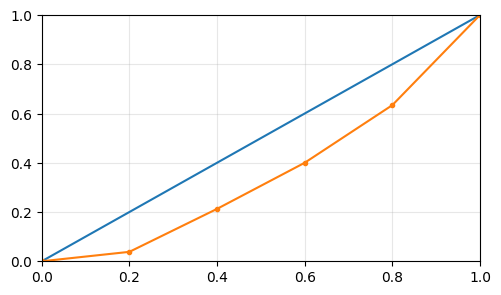

In [23]:
print('Gini, Number of interventions by each participan')
print(
    'gini:',
    round(gini_interventions, 2),
    '[1-gini]:',
    round(gini_reverse_interventions, 2),
)
fig = hf.lorenz_plot(list_interventions)

### Number of every interaction between every participant

Gini, Number of every interaction between every participant
gini: 0.52 [1-gini]: 0.48


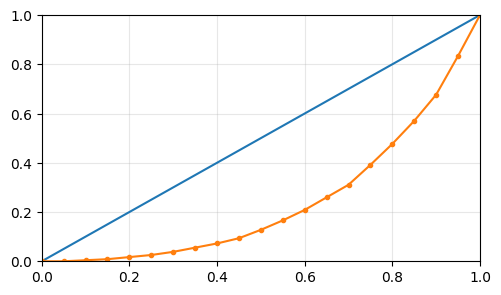

In [24]:
print('Gini, Number of every interaction between every participant')
print(
    'gini:',
    round(gini_interactions, 2),
    '[1-gini]:',
    round(gini_reverse_interactions, 2),
)
fig = hf.lorenz_plot(list_interactions)

### Number of words between every participant, taking to the next person

Gini, Number of words between every participant, taking to the next person
gini: 0.59 [1-gini]: 0.41


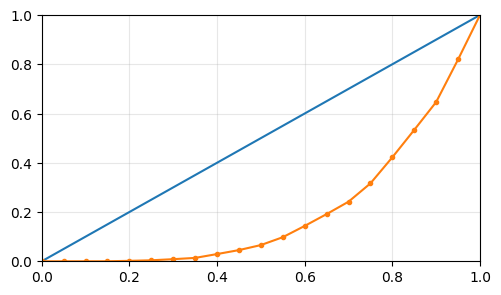

In [25]:
print('Gini, Number of words between every participant, taking to the next person')
print(
    'gini:',
    round(gini_interactions_next_wrd_cnt, 2),
    '[1-gini]:',
    round(gini_reverse_interactions_next_wrd_cnt, 2),
)
fig = hf.lorenz_plot(list_interactions_next_wrd_cnt)

### Number of words between every participant, taking to the previous person

Gini, Number of words between every participant, taking to the previous person
gini: 0.58 [1-gini]: 0.42


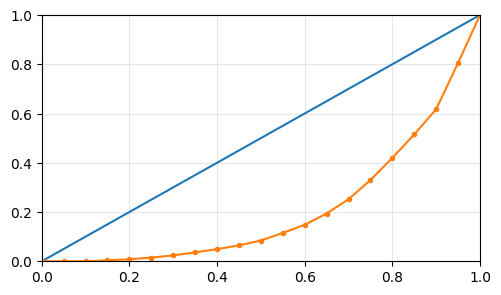

In [26]:
print('Gini, Number of words between every participant, taking to the previous person')
print(
    'gini:',
    round(gini_interactions_prev_wrd_cnt, 2),
    '[1-gini]:',
    round(gini_reverse_interactions_prev_wrd_cnt, 2),
)
fig = hf.lorenz_plot(list_interactions_prev_wrd_cnt)

### Number of words between every participant, taking to the previous person and to the next person

Gini, Number of words between every participant, taking to the previous person and talking to the next person
gini: 0.59 [1-gini]: 0.41


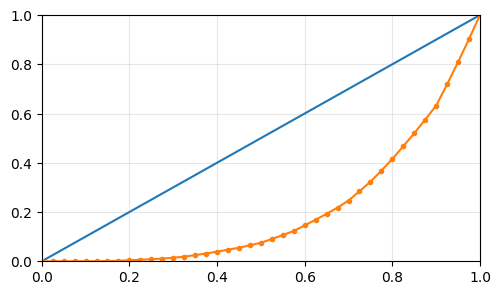

In [27]:
print('Gini, Number of words between every participant, taking to the previous person and talking to the next person')
print(
    'gini:',
    round(gini_interactions_both_wrd_cnt, 2),
    '[1-gini]:',
    round(gini_reverse_interactions_both_wrd_cnt, 2),
)
fig = hf.lorenz_plot(list_interactions_both_wrd_cnt)

## Nice Speaker Stats

In [28]:
nice_stats_col_name = {
    'action_items_count': 'Action Items',
    'idea_count': 'Idea Generation',
    'question_count': 'Questions Asked',
    'talk_time_pct': 'Speaking Time (%)',
    'interaction_count': 'Total Interactions',
    'unique_words_pct': 'Unique Words % (Idea Density)',
    'word_count': 'Word Count',
    'words_per_min': 'Words Per Minute (WPM)',
    # 'speaker': 'speaker',
    # 'text': 'text',
    # 'word_count_pct': 'word_count_pct',
    # 'talk_time_sec': 'talk_time_sec',
    # 'unique_words_count': 'unique_words_count',
}

In [29]:
nice_stats_data = (
    df_speaker_stats[nice_stats_col_name.keys()]
    .rename(columns=nice_stats_col_name)
    .sort_index(axis=0)
    # .query('name != "Mel" and name != "Jason"')
)
nice_stats_data['Unique Words % (Idea Density)'] = nice_stats_data['Unique Words % (Idea Density)'] * 100
# nice_stats_data.loc['MIN'] = nice_stats_data.min()
nice_stats_data.loc['Average'] = nice_stats_data.mean()
# nice_stats_data.loc['MAX'] = nice_stats_data.max()
nice_stats_data = nice_stats_data.transpose()

In [30]:
# nice_stats_html = nice_stats_data.astype('int').to_html(classes='')

In [31]:
# Beautify
(
    nice_stats_data
    .astype('int')
    .style
    # .format("{:.2f}")

    # .bar(axis=1, cmap='viridis', width=100, height=80)

    # .background_gradient(cmap='viridis', axis=1)
    # .background_gradient(cmap='PiYG', axis=1)
    # .background_gradient(cmap='bwr_r', axis=1)
    # .background_gradient(cmap='GnBu', axis=1)
    # .background_gradient(cmap='PuBuGn', axis=1)
    # .background_gradient(cmap='BuGn', axis=1)
    # .background_gradient(cmap='YlGn', axis=1)
    
    .highlight_max(axis=1, color='pink').highlight_min(axis=1, color='powderblue')
)

name,Brandy,Daion,Felipe,Jason,Zoe,Average
Action Items,7,5,9,7,3,6
Idea Generation,116,44,29,33,8,46
Questions Asked,37,33,4,34,1,21
Speaking Time (%),46,14,14,19,4,20
Total Interactions,86,55,41,45,9,47
Unique Words % (Idea Density),24,32,32,33,50,34
Word Count,6637,2289,1990,2746,519,2836
Words Per Minute (WPM),185,172,170,174,166,173


## Bar Plots

In [32]:
df_speaker_stats[['action_items_count','words_per_min']].transpose()

name,Brandy,Daion,Jason,Felipe,Zoe
action_items_count,7.000000,5.0000,7.000000,9.000000,3.000000
words_per_min,185.689639,172.3772,174.536141,170.017338,166.677434


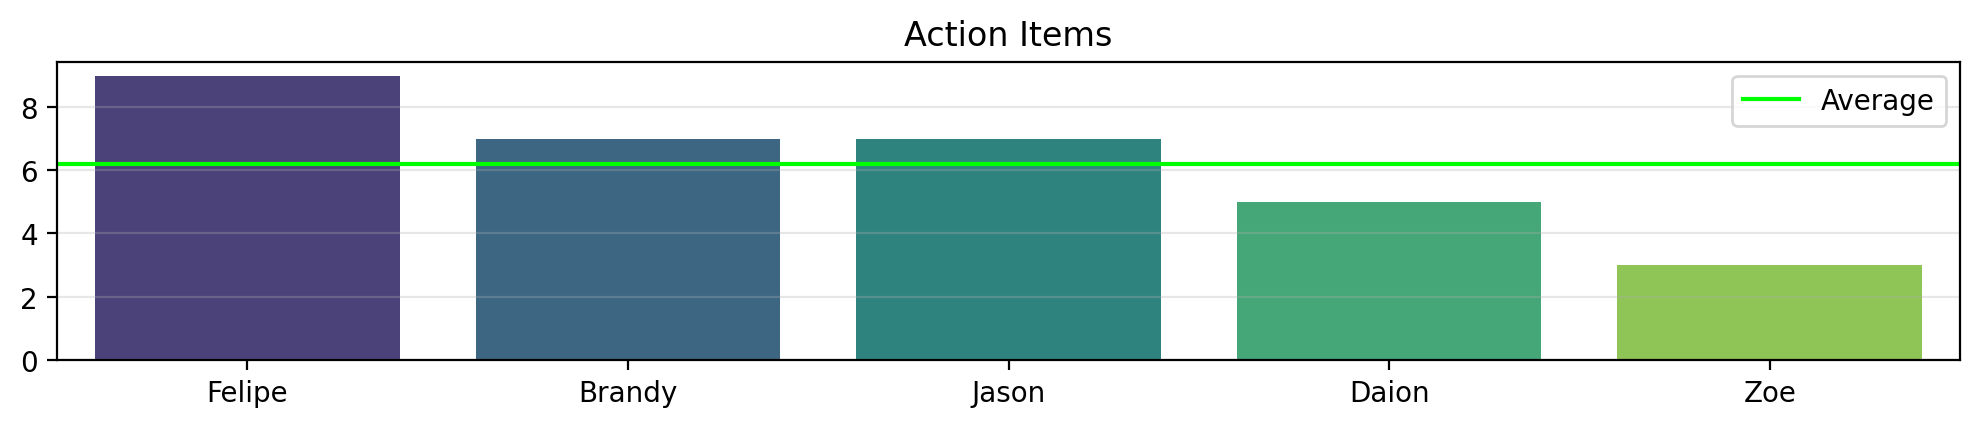

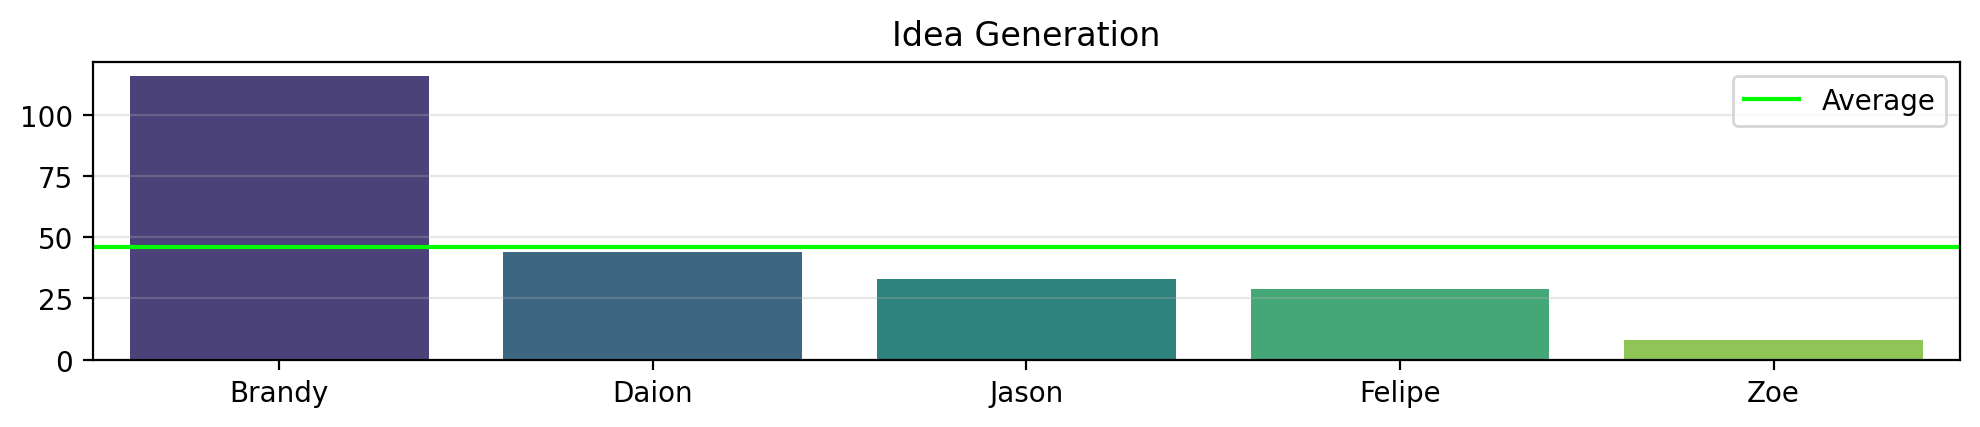

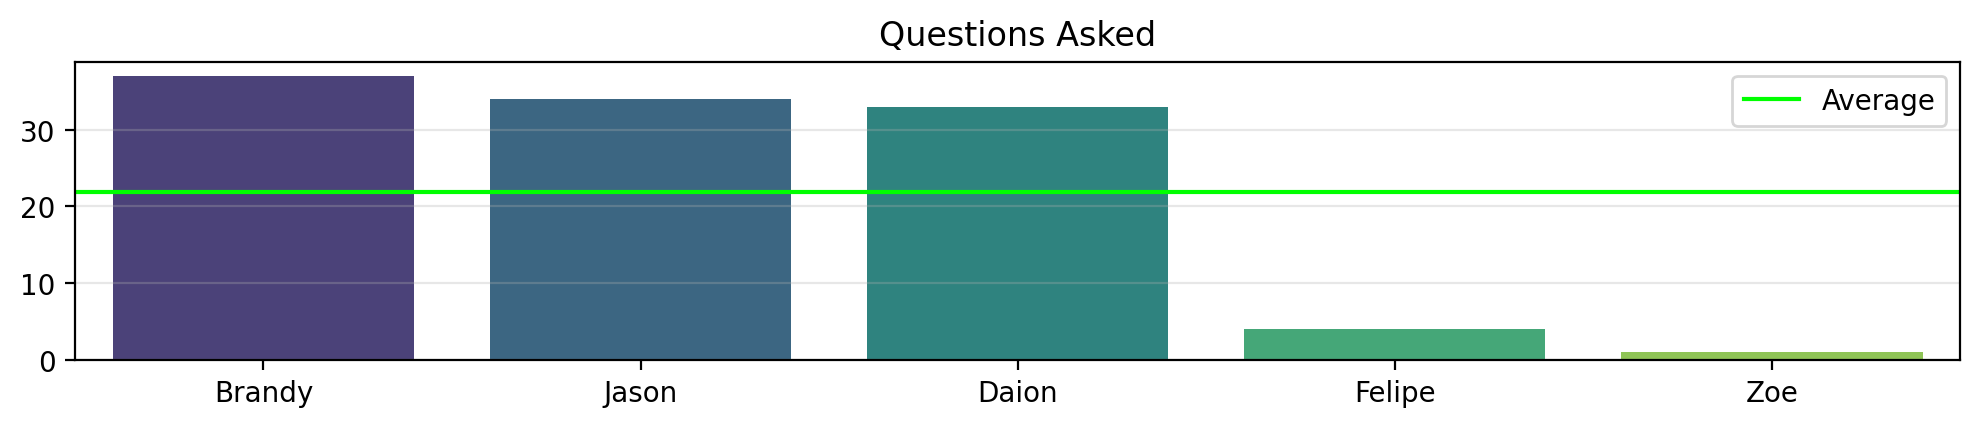

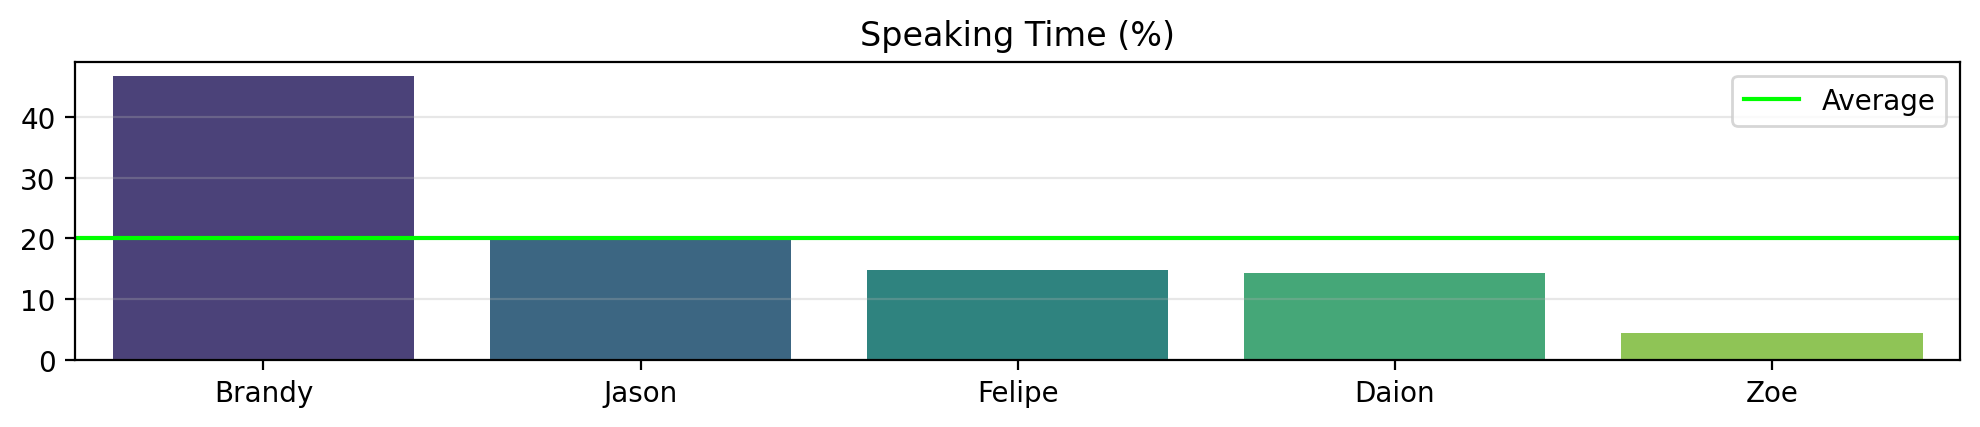

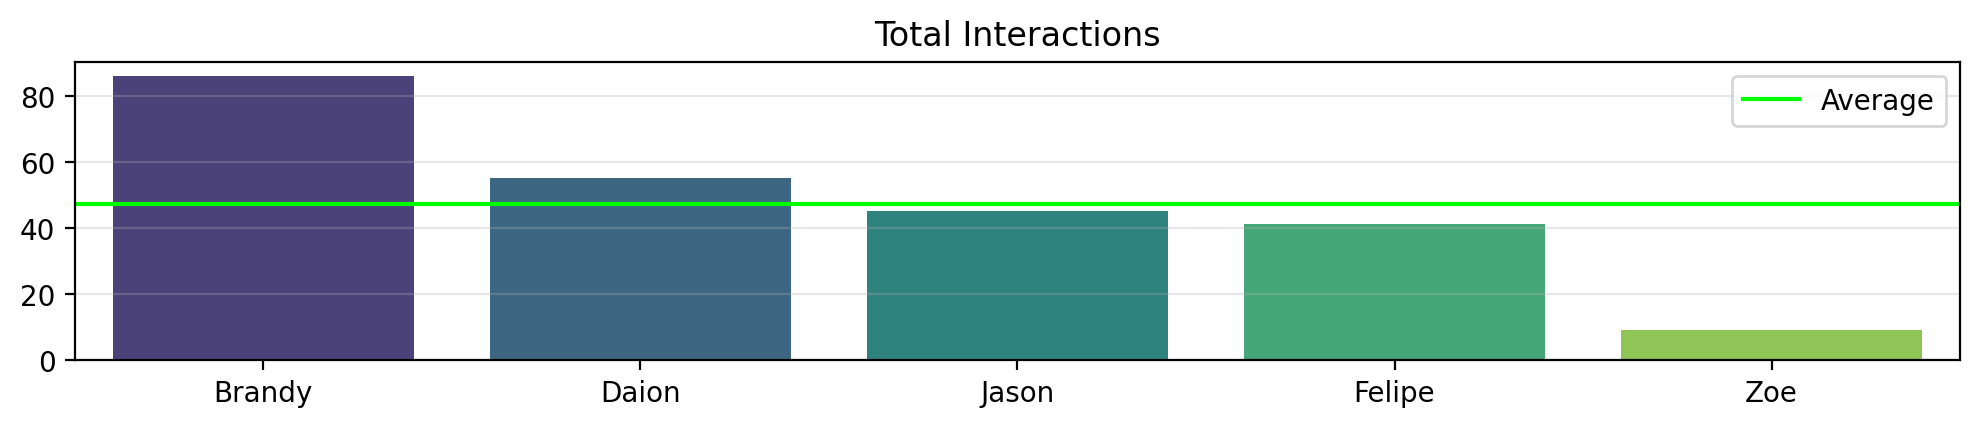

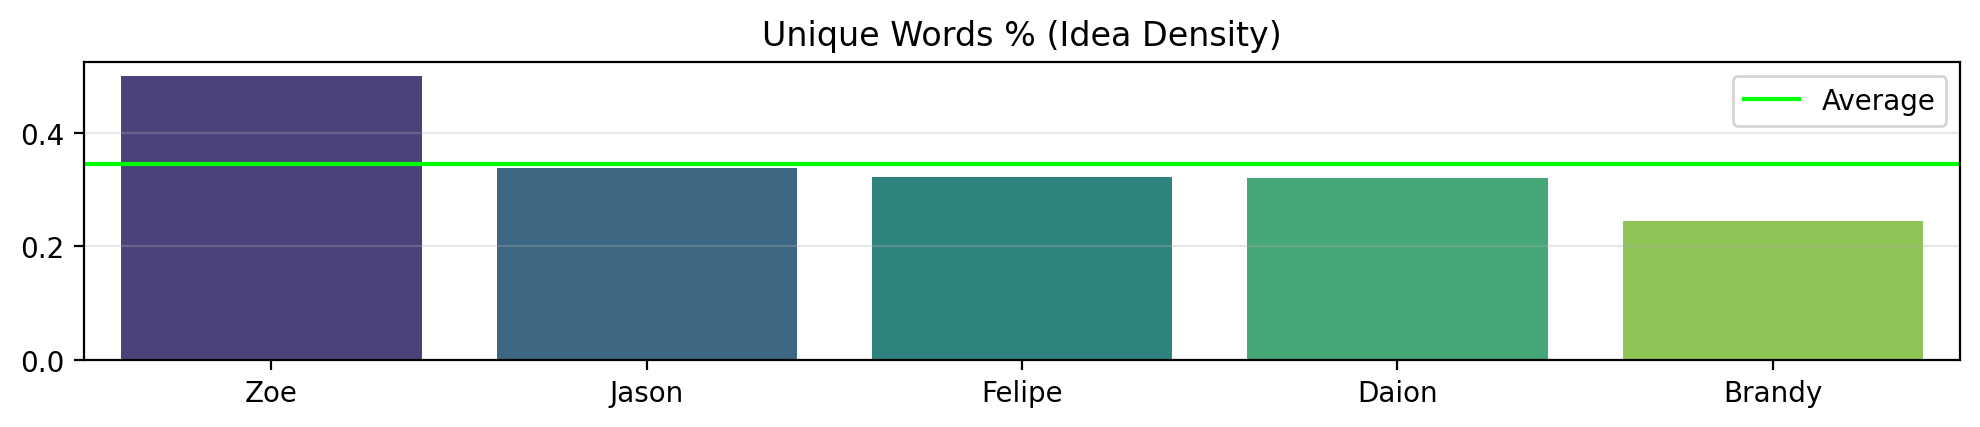

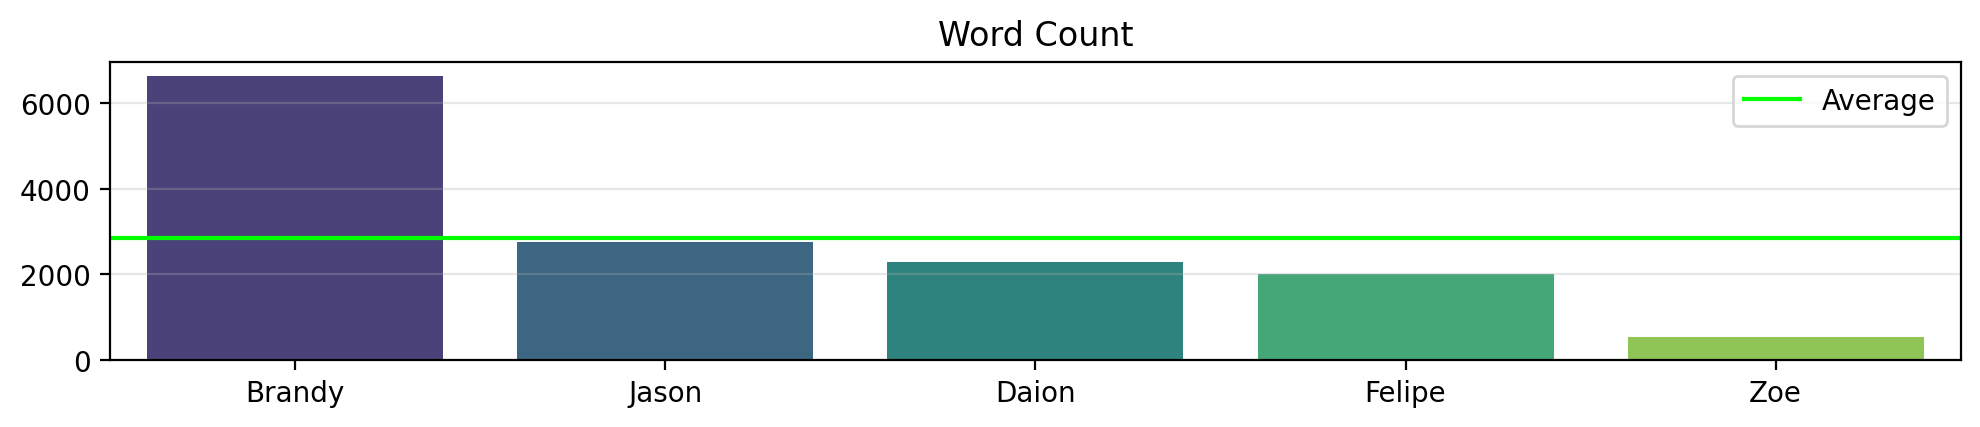

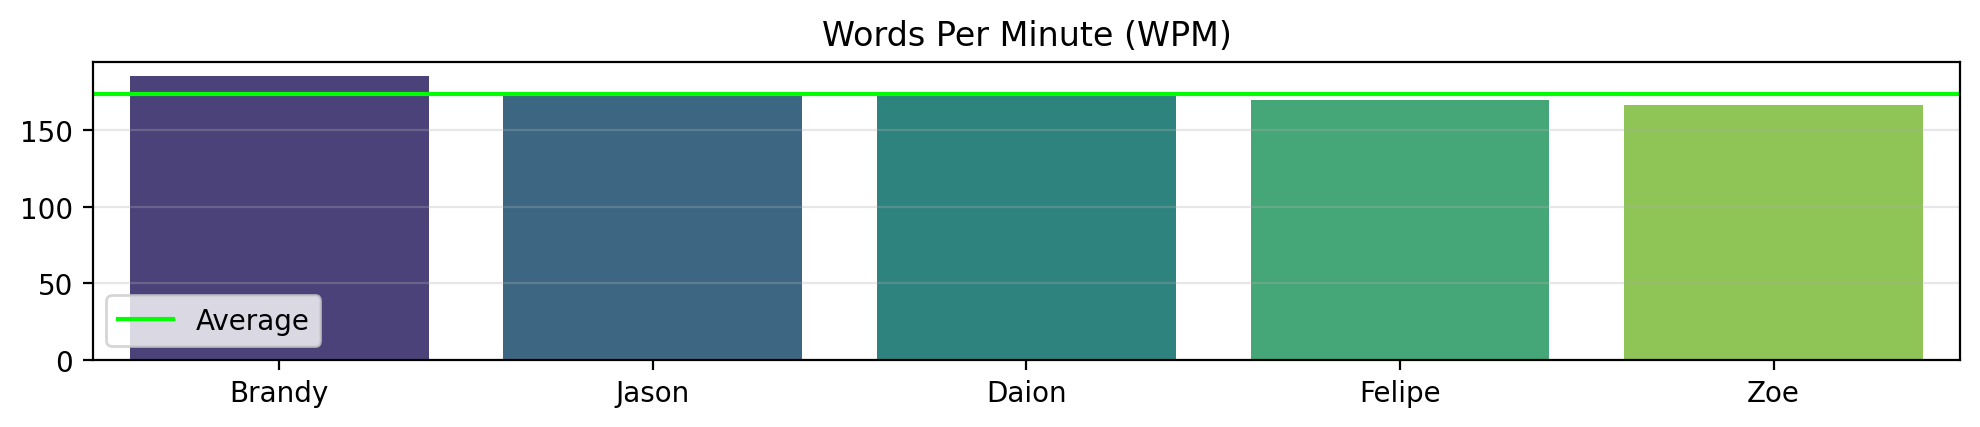

In [33]:
import lib.helper_functions as hf
%config InlineBackend.figure_format = "retina"

figs_barplot = {}
for stat in nice_stats_col_name:
    # print(stat, nice_stats_col_name[stat])
    figs_barplot[stat] = hf.barplot(
        data=df_speaker_stats[[stat]]
        .sort_values(by=stat, ascending=False)
        .transpose(),
        title=nice_stats_col_name[stat],
        # xlabel='Speaker',
        # ylabel='Action Items',
    )

## Action pie chart

In [34]:
df_speaker_stats['action_items_count'].index.to_list(), df_speaker_stats['action_items_count'].to_list()

(['Brandy', 'Daion', 'Jason', 'Felipe', 'Zoe'], [7, 5, 7, 9, 3])

name
Brandy    7
Daion     5
Felipe    9
Jason     7
Zoe       3
Name: action_items_count, dtype: int64

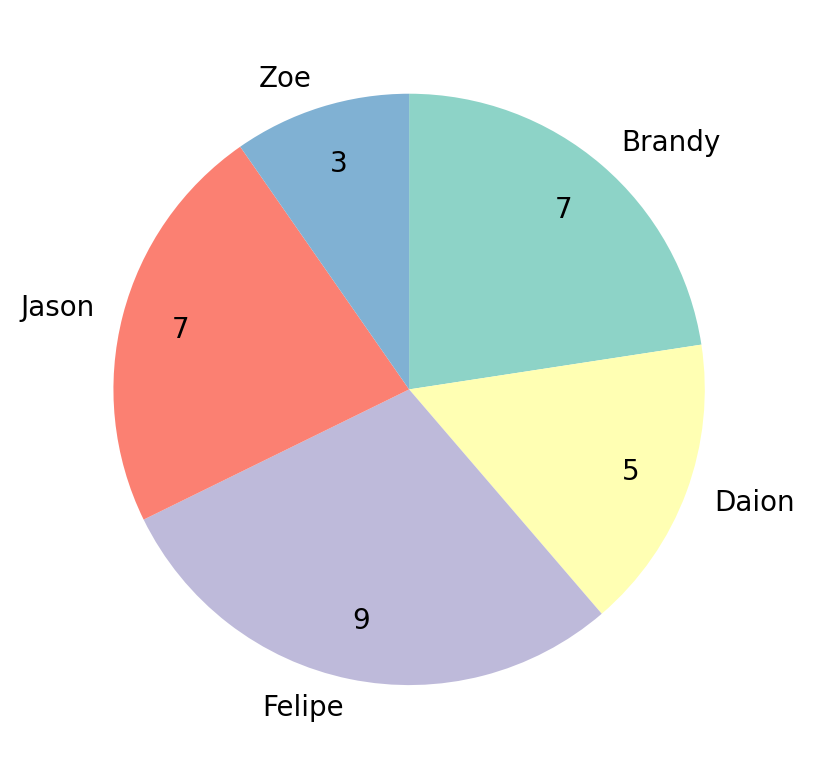

In [54]:
import matplotlib.pyplot as plt

# labels = 'Frogs', 'Hogs', 'Dogs', 'Logs'
# sizes = [15, 30, 45, 10]
# fig, ax = plt.subplots()
# ax.pie(sizes, labels=labels)

fig_action_items, ax = plt.subplots()
colors = plt.get_cmap('Set3').colors
_df_speaker_stats = df_speaker_stats['action_items_count'].sort_index()
ax.pie(
    _df_speaker_stats.to_list(),
    labels=_df_speaker_stats.index.to_list(),
    autopct=lambda x: round(x * _df_speaker_stats.sum() / 100),
    pctdistance=0.8,
    colors=colors,
    counterclock=False,
    startangle=90,
);
_df_speaker_stats

## Sentiment evolution

### Overall Sentiment evolution

In [36]:
df_sentiment['sentiment'].value_counts(normalize=True)

sentiment
NEUTRAL     0.691888
NEGATIVE    0.179277
POSITIVE    0.128834
Name: proportion, dtype: float64

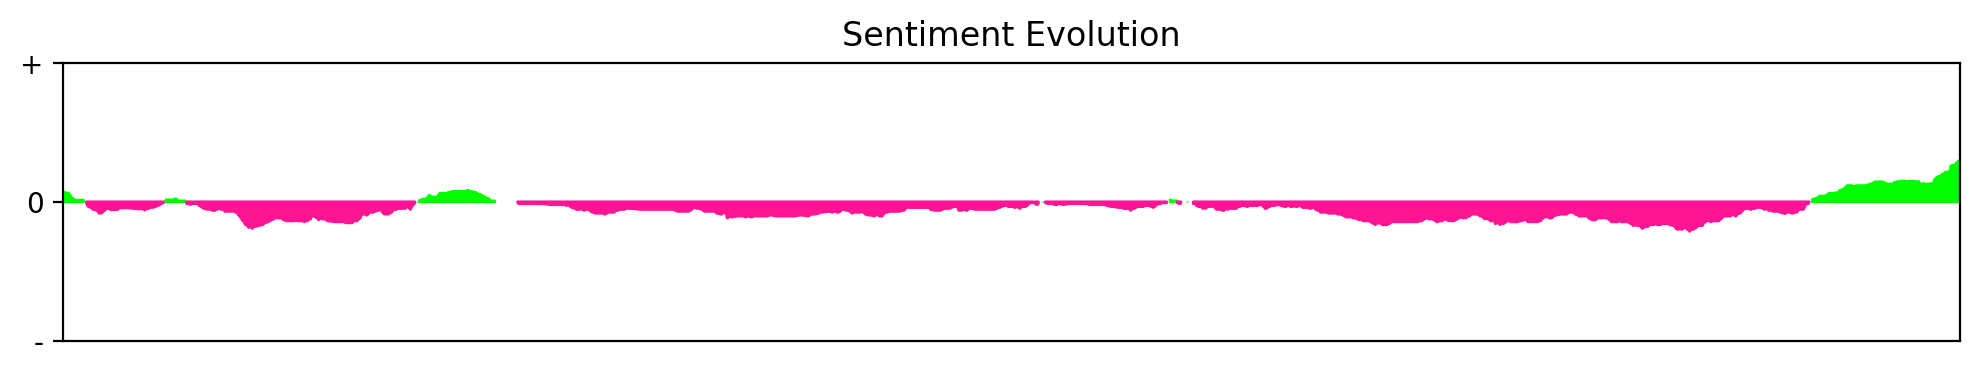

In [37]:
import matplotlib.pyplot as plt
# df_sentiment.set_index('start')['sentiment_value'].plot(alpha=0.2)

_window_size_pct = 0.1
_window_size = int(
    df_sentiment.set_index('start')['sentiment_value'].shape[0] * _window_size_pct
)  # Window size as percentage
df_sentiment_mean = df_sentiment.set_index('start')['sentiment_value'].rolling(window=_window_size, center=True, min_periods=1).mean()
# ax = df_sentiment.set_index('start')['sentiment_value'].plot()
ax = df_sentiment_mean.plot(figsize=(10, 2), alpha=0)
ax.set_ylim(-1, 1)
# ax.axhline(y=0, color='lightgray', linestyle='--', linewidth=1)
ax.fill_between(
    df_sentiment_mean.index,
    df_sentiment_mean,
    0,
    where=(df_sentiment_mean > 0),
    color='lime',
    alpha=1,
)
ax.fill_between(
    df_sentiment_mean.index,
    df_sentiment_mean,
    0,
    where=(df_sentiment_mean < 0),
    color='deeppink',
    alpha=1,
)
ax.set_yticks([-1, 0, 1])
# ax.set_yticklabels(['Negative', 'Neutral', 'Positive'])
ax.set_yticklabels(['-', '0', '+'])
ax.set_xticks([])
ax.set_xlabel('')
ax.set_title('Sentiment Evolution')
plt.tight_layout()
plt.autoscale(tight=True, axis='x')
# df_sentiment.set_index('start')['sentiment_value'].plot()
fig_convo_sentiment_evo = ax.figure

In [38]:
ax

<Axes: title={'center': 'Sentiment Evolution'}>

### Sentiment evolution per person

In [39]:
df_sentiment[['name','sentiment_value']].describe()#.groupby('name').std()

,name,sentiment_value
count,1467,1467
unique,5,3
top,Brandy,0
freq,679,1015


In [40]:
df_sentiment.groupby('name')['sentiment_value'].apply(
    lambda x: pd.DataFrame((x.sum(),x.std(),x.mean()), index=('sum','std','mean'))
).unstack().droplevel(0, axis=1).sort_values('mean').style.background_gradient(cmap='RdPu', axis=1)

,sum,std,mean
name,,,
Daion,-42.000000,0.573189,-0.157303
Brandy,-29.000000,0.526245,-0.042710
Jason,-10.000000,0.604116,-0.033784
Felipe,3.000000,0.511178,0.015306
Zoe,4.000000,0.580895,0.137931


Brandy (1467,)
Daion (1467,)
Felipe (1467,)
Jason (1467,)
Zoe (1467,)


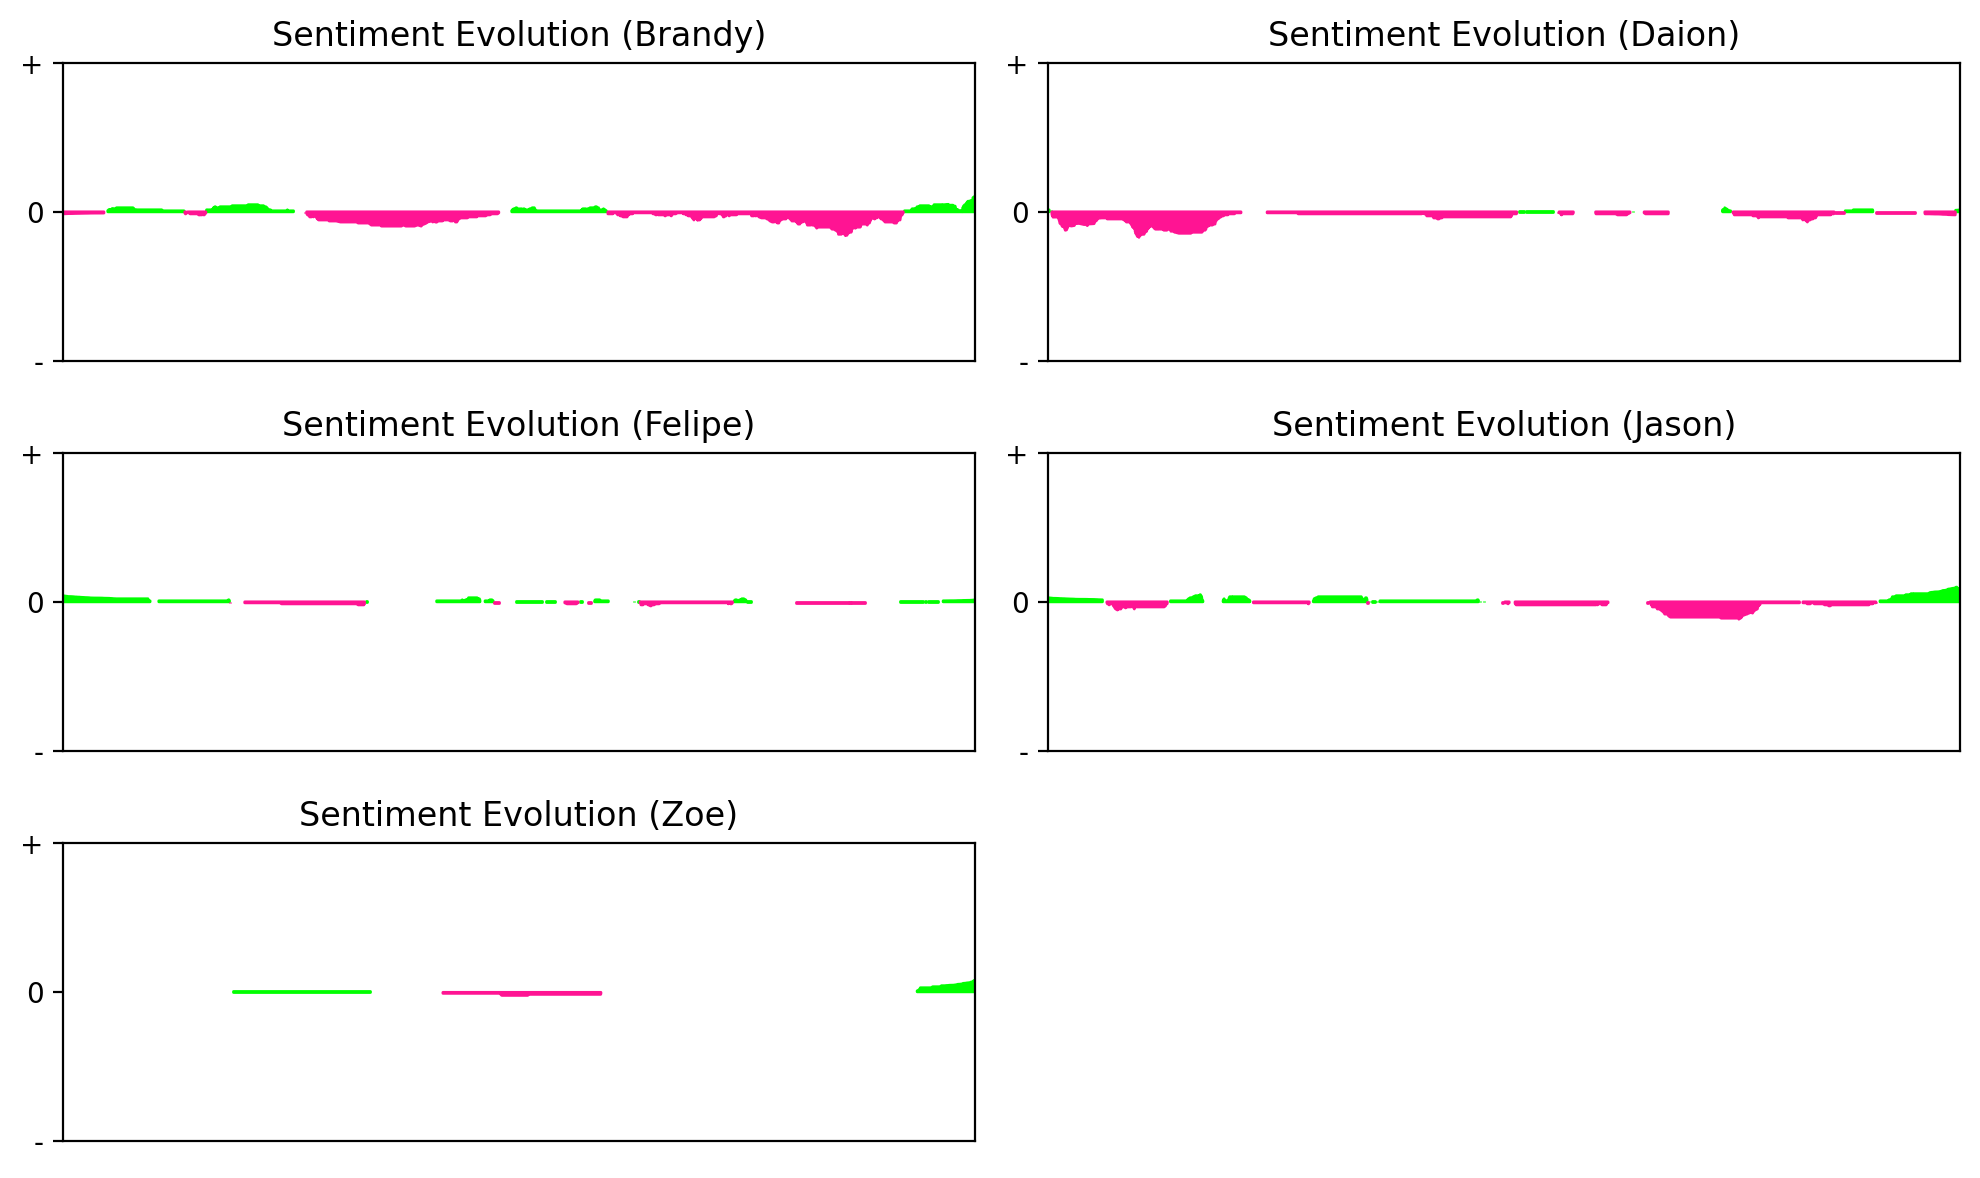

In [41]:
import matplotlib.pyplot as plt
import math

pltlogger = logging.getLogger('matplotlib')
pltlogger.setLevel(logging.WARNING)

ncols = 2
nrows = math.ceil(df_speaker_stats['speaker'].shape[0] / ncols)
fig_speaker_sentiment_evo, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(10, nrows * 2))
# Don't show axis for not plotted positions
noshow_count = nrows * ncols - df_speaker_stats['speaker'].shape[0]
for i in range(nrows * ncols - 1, nrows * ncols - 1 - noshow_count, -1):
    axes[i // ncols, i % ncols].axis("off")  # Don't show

# for name in df_sentiment['name'].unique():
for i, name in enumerate(sorted(df_sentiment['name'].unique())):
    _df_sentiment_by_person = (
        df_sentiment.set_index('start')
        .query(f'name == "{name}"')['sentiment_value']
        .reindex(df_sentiment.set_index('start').index, fill_value=0)
    )

    # _df_sentiment_by_person.reset_index(drop=True).plot(
    #     alpha=0.2,
    #     )

    # Window size as percentage
    _window_size_pct = 0.10
    _window_size_computed = int(_df_sentiment_by_person.shape[0] * _window_size_pct)
    _window_size = max(1, _window_size_computed)

    df_sentiment_mean = (
        _df_sentiment_by_person
        # .reset_index(drop=True)
        .rolling(window=_window_size, center=True, min_periods=1).mean()
    )
    print(name, df_sentiment_mean.shape)
    if len(axes.shape) == 1:
        ax = df_sentiment_mean.plot(ax=axes[i % ncols], alpha=0)
    else:
        ax = df_sentiment_mean.plot(ax=axes[i // ncols, i % ncols], alpha=0)
    ax.fill_between(
        df_sentiment_mean.index,
        df_sentiment_mean,
        0,
        where=(df_sentiment_mean > 0),
        color='lime',
        alpha=1,
    )
    ax.fill_between(
        df_sentiment_mean.index,
        df_sentiment_mean,
        0,
        where=(df_sentiment_mean < 0),
        color='deeppink',
        alpha=1,
    )
    ax.set_yticks([-1, 0, 1])
    # ax.set_yticklabels(['Negative', 'Neutral', 'Positive'])
    ax.set_yticklabels(['-', '0', '+'])
    ax.set_xticks([])
    ax.set_xlabel('')
    ax.set_title(f'Sentiment Evolution ({name})')
    ax.autoscale(tight=True, axis='x')
    # break
    # plt.show()
fig_speaker_sentiment_evo.tight_layout()

## Words per minute

### Words per minute evolution (Excitement proxy)

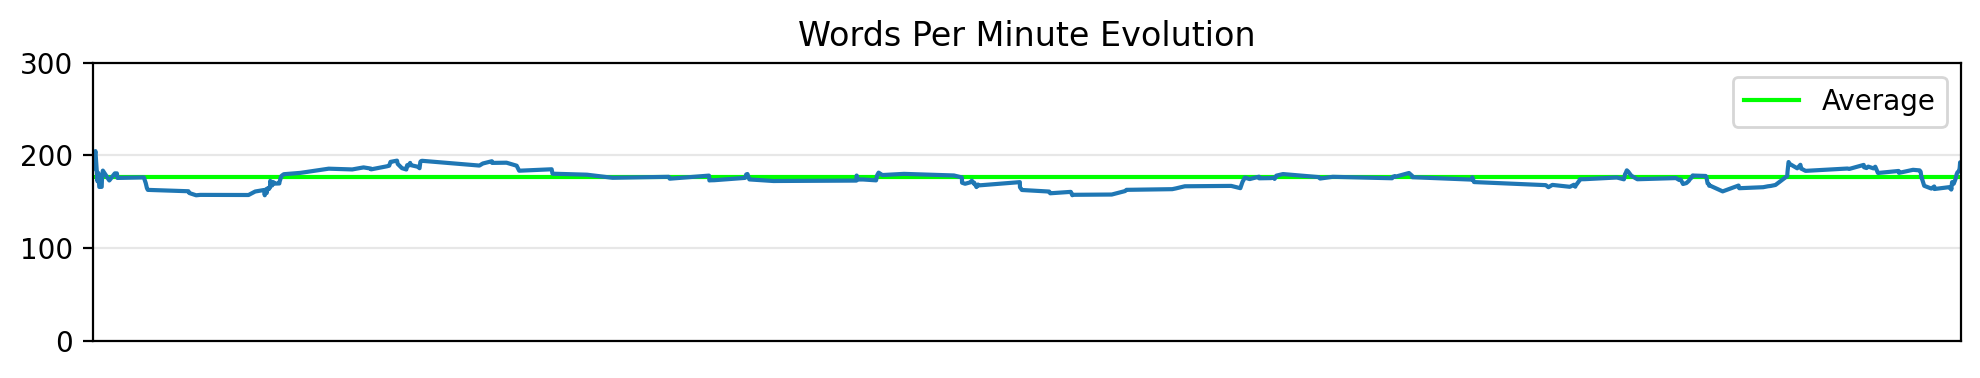

In [42]:
_window_size_pct = 0.1
_window_size = int(
    df_utter.set_index('start')['words_per_min'].shape[0] * _window_size_pct
)  # Window size as percentage

ax = (
    df_utter.set_index('start')['words_per_min']
    .rolling(window=_window_size, min_periods=1)
    .mean()
    .plot(figsize=(10, 2), label='')
)
ax.set_title('Words Per Minute Evolution')
ax.set_xticks([])
ax.set_xlabel('')
ax.set_ylim(0, 300)
ax.autoscale(tight=True, axis='x')
ax.grid(axis='y', alpha=0.3)
ax.axhline(y=df_utter.set_index('start')['words_per_min'].mean(), color='lime', zorder=-1, label='Average')
ax.legend()
plt.tight_layout()
plt.autoscale(tight=True, axis='x')

fig_convo_wpm = ax.figure

### Words per minute evolution (Excitement per person proxy)

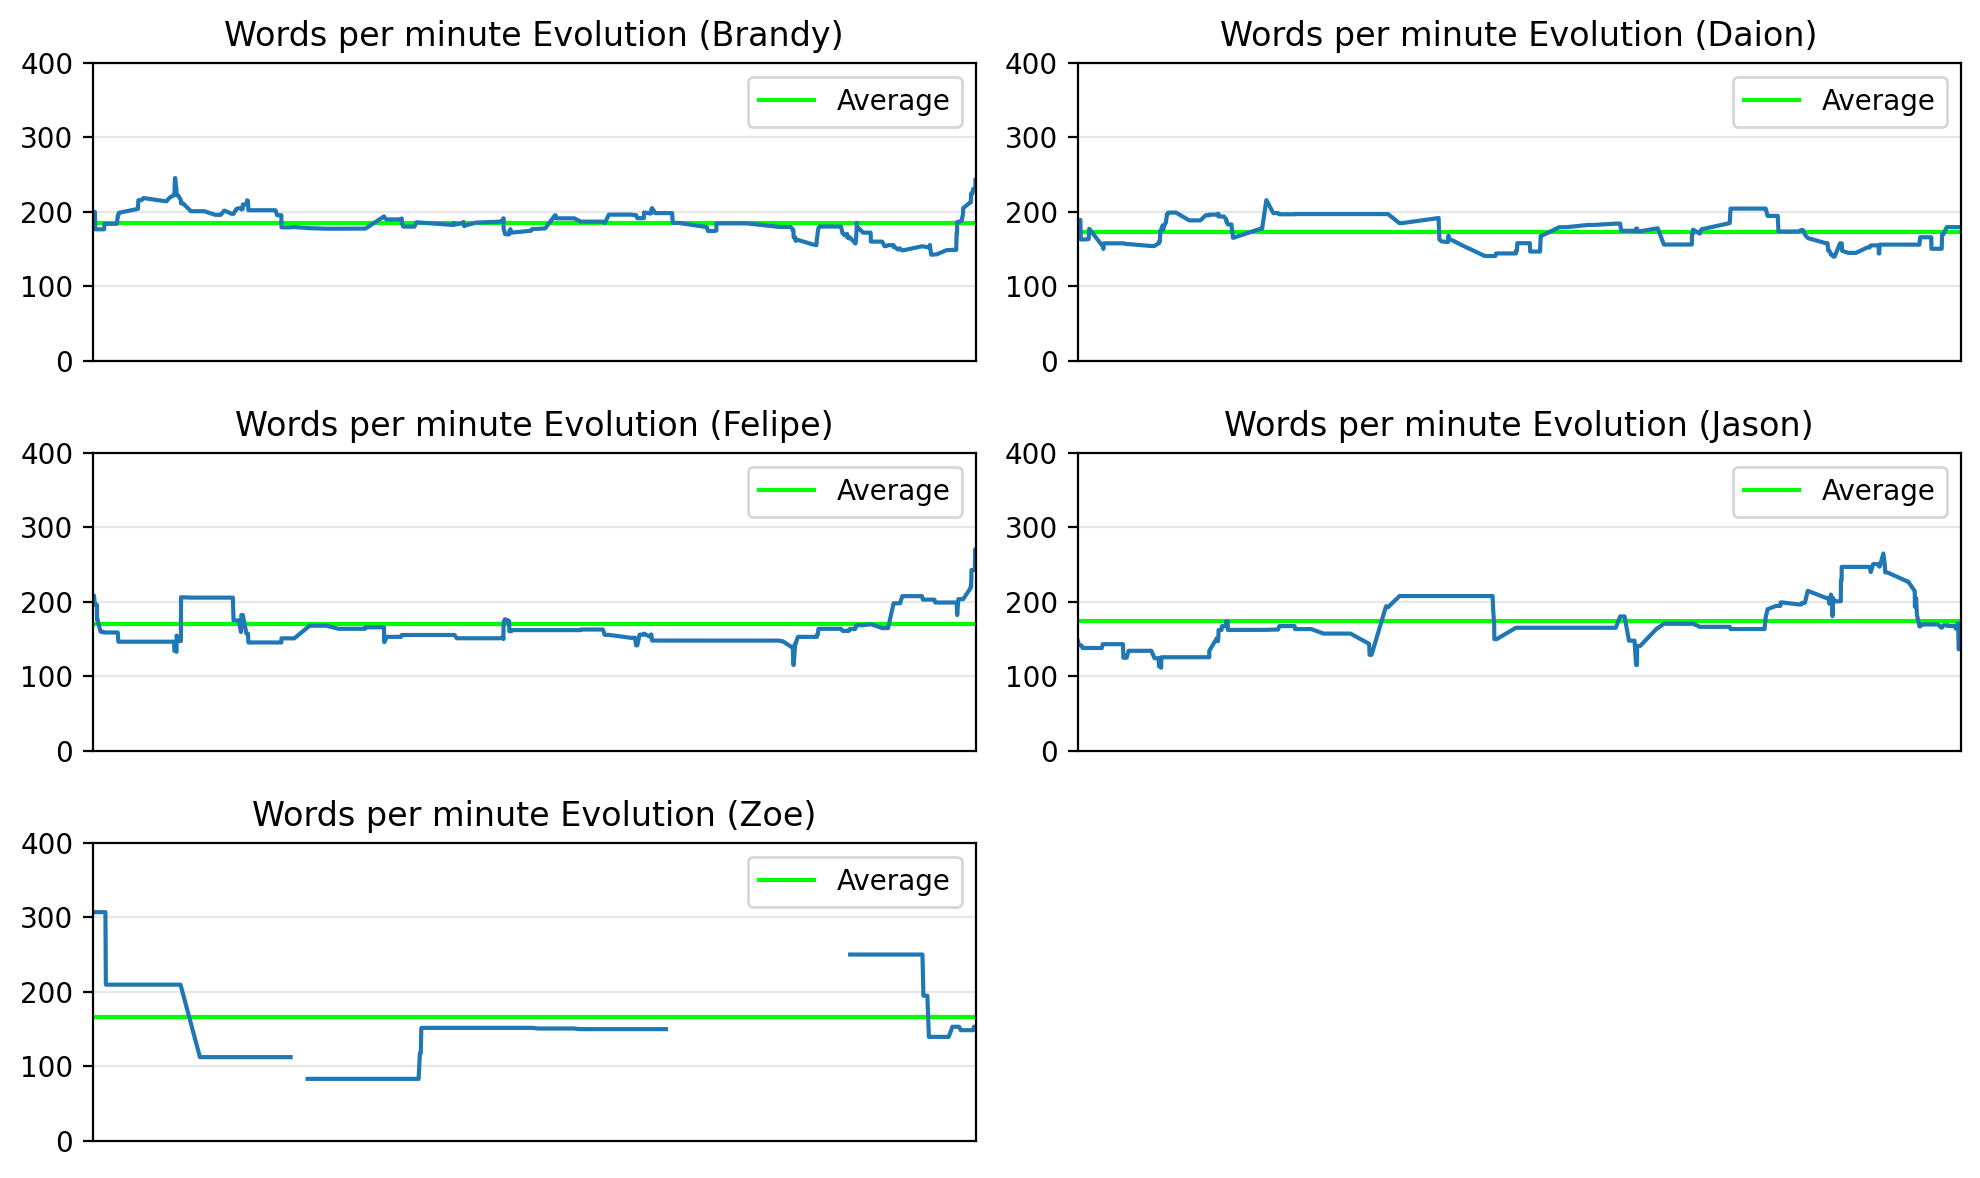

In [43]:
import matplotlib.pyplot as plt

pltlogger = logging.getLogger('matplotlib')
pltlogger.setLevel(logging.WARNING)

ncols = 2
nrows = math.ceil(df_speaker_stats['speaker'].shape[0] / ncols)
fig_speaker_wpm, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(10, nrows * 2))
# Don't show axis for not plotted positions
noshow_count = nrows * ncols - df_speaker_stats['speaker'].shape[0]
for i in range(nrows * ncols - 1, nrows * ncols - 1 - noshow_count, -1):
    axes[i // ncols, i % ncols].axis("off")  # Don't show

# for name in df_utter['name'].unique():
for i, name in enumerate(sorted(df_sentiment['name'].unique())):

    _df_words_per_min_by_person = (
        df_utter.set_index('start')
        .query(f'name == "{name}"')['words_per_min']
        .reindex(df_utter.set_index('start').index)
    )
    # _df_sentiment_by_person = df_sentiment.set_index('start').query(f'name == "{name}"')['sentiment_value'].reindex(df_sentiment.set_index('start').index, fill_value=0)

    # (
    #     _df_words_per_min_by_person
    #     # .reset_index(drop=True)
    #     .plot(
    #         # marker='+',
    #         # linestyle='none',
    #         alpha=0.2,
    #     )
    # )

    # Window size as percentage
    _window_size_pct = 0.10
    _window_size_computed = int(_df_words_per_min_by_person.shape[0] * _window_size_pct)
    _window_size = max(1, _window_size_computed)

    df_words_per_min_mean = (
        _df_words_per_min_by_person
        # .reset_index(drop=True)
        .rolling(window=_window_size, center=True, min_periods=1)
        .mean()
    )
    if len(axes.shape) == 1:
        ax = df_words_per_min_mean.plot(label='', ax=axes[i % ncols])
    else:
        ax = df_words_per_min_mean.plot(label='', ax=axes[i // ncols, i % ncols])
    ax.set_title(f'Words per minute Evolution ({name})')
    ax.set_ylim(0, 400)
    ax.set_xticks([])
    ax.set_xlabel('')
    ax.autoscale(tight=True, axis='x')
    ax.grid(axis='y', alpha=0.3)
    ax.axhline(y=_df_words_per_min_by_person.mean(), color='lime', zorder=-1, label='Average')
    ax.legend()
fig_speaker_wpm.tight_layout()

## Chord diagram

DEBUG:urllib3.connectionpool:connectionpool.py(1049):_new_conn 2025-05-19 21:29:42,844
Starting new HTTPS connection (1): plotapi.com:443


Your PlotAPI API key has been saved in your local environment. You will not need to set it again.


DEBUG:urllib3.connectionpool:connectionpool.py(544):_make_request 2025-05-19 21:29:43,747
https://plotapi.com:443 "POST /chord/png?scale=1 HTTP/1.1" 200 None


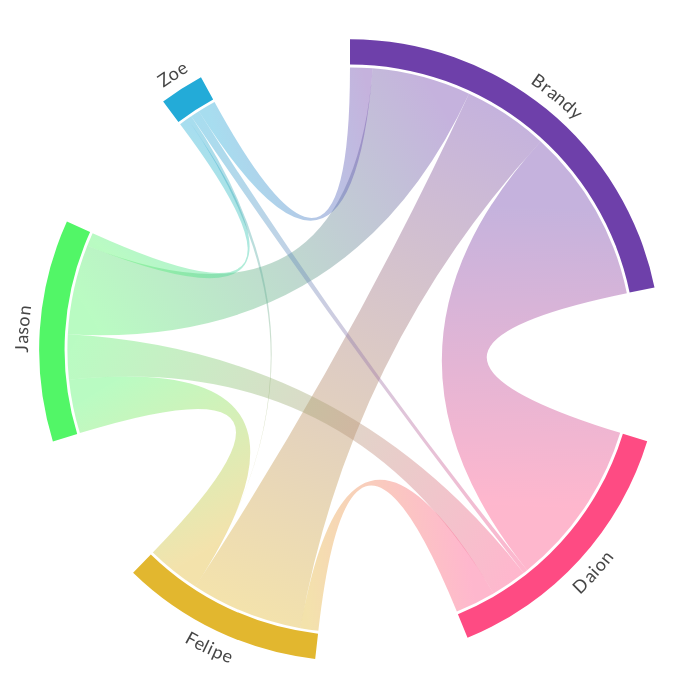

In [44]:
# Chord interactions with previous person
from plotapi import Chord

Chord.api_key(os.getenv('PLOTAPI_KEY'))

_df_interaction = df_interactions_prev.iloc[:-1, :-1]

chord_interactions_prev = Chord(
    matrix=_df_interaction.values.tolist(),
    names=_df_interaction.index.to_list(),
    padding=0.5,
    curved_labels=True,
    conjunction="&",
    verb="interacted",
    noun="times",
    popup_width=100,
)

chord_interactions_prev.show_png(scale=1)
# chord_interactions_prev.to_html(path_work_dir.joinpath('chord_interaction_prev.html'))

In [45]:
# png = chord.get_png()
# buf_chord = buf = io.BytesIO(png)
# image_chord = Image.open(buf_chord)
# # buf_chord.seek(0)  # Important: go to the start of the buffer


## Key Contributions

In [46]:
import textwrap
for speaker in speaker_map:
    print('\n\n', speaker_map[speaker]['name'])
    for quote in speaker_map[speaker]['quotes']:
        print('*', quote['tagline'])
        print(textwrap.fill(quote['quote'], width=100))



 Brandy
* Navigating a Toxic Workplace
I meet her where she is. I have no expectations that anything is going to change. I have no
expectations of making this a joyous tenure.
* A Unicorn in the Field
I come with 21 years [in learning and development] and I come with the business knowledge. So I'm a
unicorn in the group.
* Setting Boundaries and Guardrails
I had to recognize that it is okay for me to place boundaries and parameters around... I didn't give
them everything... because they don't need to know that.


 Daion
* On overcoming a difficult breakup and self-advocacy
I think I've made following your gut is, like, the best thing. And I've learned to forgive myself
and not be mad at myself. If anything, to applaud myself for actually standing up for myself,
because I feel like if I still continued, I don't know what that would look like. Six months later,
I don't know if I would be happy.
* On recognizing and addressing toxic relationships
The biggest issue I had was how this per

## Summary by participant

In [47]:
import textwrap

for speaker in speaker_map:
    print('\n\n', speaker_map[speaker]['name'])
    print(textwrap.fill(speaker_map[speaker]['summary'], width=100)) # Remove `textwrap.fill` to not have line breaks
    # print(speaker_map[speaker]['summary'])



 Brandy
This transcript details a person's struggles navigating a challenging work environment.  They are a
head of strategy, data analytics, and technology in corporate learning and development for a large,
global organization, and are facing difficulties collaborating with their leadership team, who lack
learning and development backgrounds.  The speaker's direct superior is described as a highly
demanding and even toxic leader, creating a stressful and demoralizing atmosphere.  The speaker
discusses strategies for managing this difficult superior, including setting boundaries, preparing
meticulously for meetings, and focusing on achieving objectives despite the challenging dynamics.
The speaker also touches upon their personal growth, career aspirations, and the broader
organizational challenges stemming from recent restructuring and leadership changes.


 Daion
The conversation centers on the speaker's recent difficult breakup,  characterized by the speaker
confronting their ex-b

## Action items

In [48]:
import textwrap
for speaker in speaker_map:
    print('\n\n', speaker_map[speaker]['name'])
    for action in speaker_map[speaker]['actions']:
        print('*', action['title'])
        print(textwrap.fill(action['action'], width=100))



 Brandy
* Prepare for Meeting with CLO
Develop and prepare a comprehensive plan for the upcoming meeting with the Chief Learning Officer,
including a draft plan to share beforehand.
* Facilitate Collaborative Metric Definition
Lead a collaborative workshop with the leadership team to define clear and agreed-upon success
metrics for the learning and development department, including program-specific measures.
* Develop and Implement a Success Metric Framework
Develop and implement a framework for auditing and measuring program effectiveness, ensuring all
leaders understand and agree upon it.
* Improve Communication with CLO
Improve communication with the Chief Learning Officer by learning to communicate effectively in her
preferred style, while maintaining personal integrity.
* Foster Team Collaboration
Encourage greater collaboration and teamwork among the leadership team, reducing reliance on the CLO
for decision-making.
* Develop Brandy Consulting
Continue developing Brandy Consult

# PDF generation

In [49]:
_df = df_interactions_next.iloc[:-1, :-1]  # We remove one to avoid the All column or row
size = _df.shape[0]
for i in range(size):
    # print(_df.iat[i, i])
    _df.iat[i, i] = pd.NA
_list = _df.melt()['value'].dropna().tolist()
gini_reverse = round(100 * (1 - hf.gini(_list)), 2)


import lib.pdf_functions as pdffn
import lib.helper_functions as hf
import traceback

try:
    pdffn.create_report(
    images_barplot = [hf.figure_to_image(figs_barplot[fig]) for fig in figs_barplot],
    image_chord=hf.png_to_image(chord_interactions_prev.get_png()),
    image_convo_sentiment_evo = hf.figure_to_image(fig_convo_sentiment_evo),
    image_speaker_sentiment_evo = hf.figure_to_image(fig_speaker_sentiment_evo),
    image_convo_wpm = hf.figure_to_image(fig_convo_wpm),
    image_speaker_wpm = hf.figure_to_image(fig_speaker_wpm),
    image_action_items = hf.figure_to_image(fig_action_items),
    path_report_assets=path_report_assets,
    summaries=summaries,
    gini_reverse_interventions=gini_reverse_interventions,
    gini_reverse_interactions=gini_reverse_interactions,
    gini_reverse_interactions_both_wrd_cnt=gini_reverse_interactions_both_wrd_cnt,
    nice_stats_data=nice_stats_data,
    speaker_map=speaker_map,
    path_reports_dir=path_reports_dir,
)
except Exception as e:
    print(e)
    traceback.print_exc()

DEBUG:urllib3.connectionpool:connectionpool.py(544):_make_request 2025-05-19 21:29:46,027
https://plotapi.com:443 "POST /chord/png HTTP/1.1" 200 None
INFO:root:pdf_functions.py(187):create_report 2025-05-19 21:29:48,876
Creating PDF report.
INFO:root:pdf_functions.py(427):create_report 2025-05-19 21:29:49,518
...created pdf [/Users/felipe/Documents/development/python projects/mmjb_reports/output/2025 Q2 Group 1 Meet 4 - Brandy Ford/reports/report_group.pdf].


# IDEAS

## Visualize Chapters

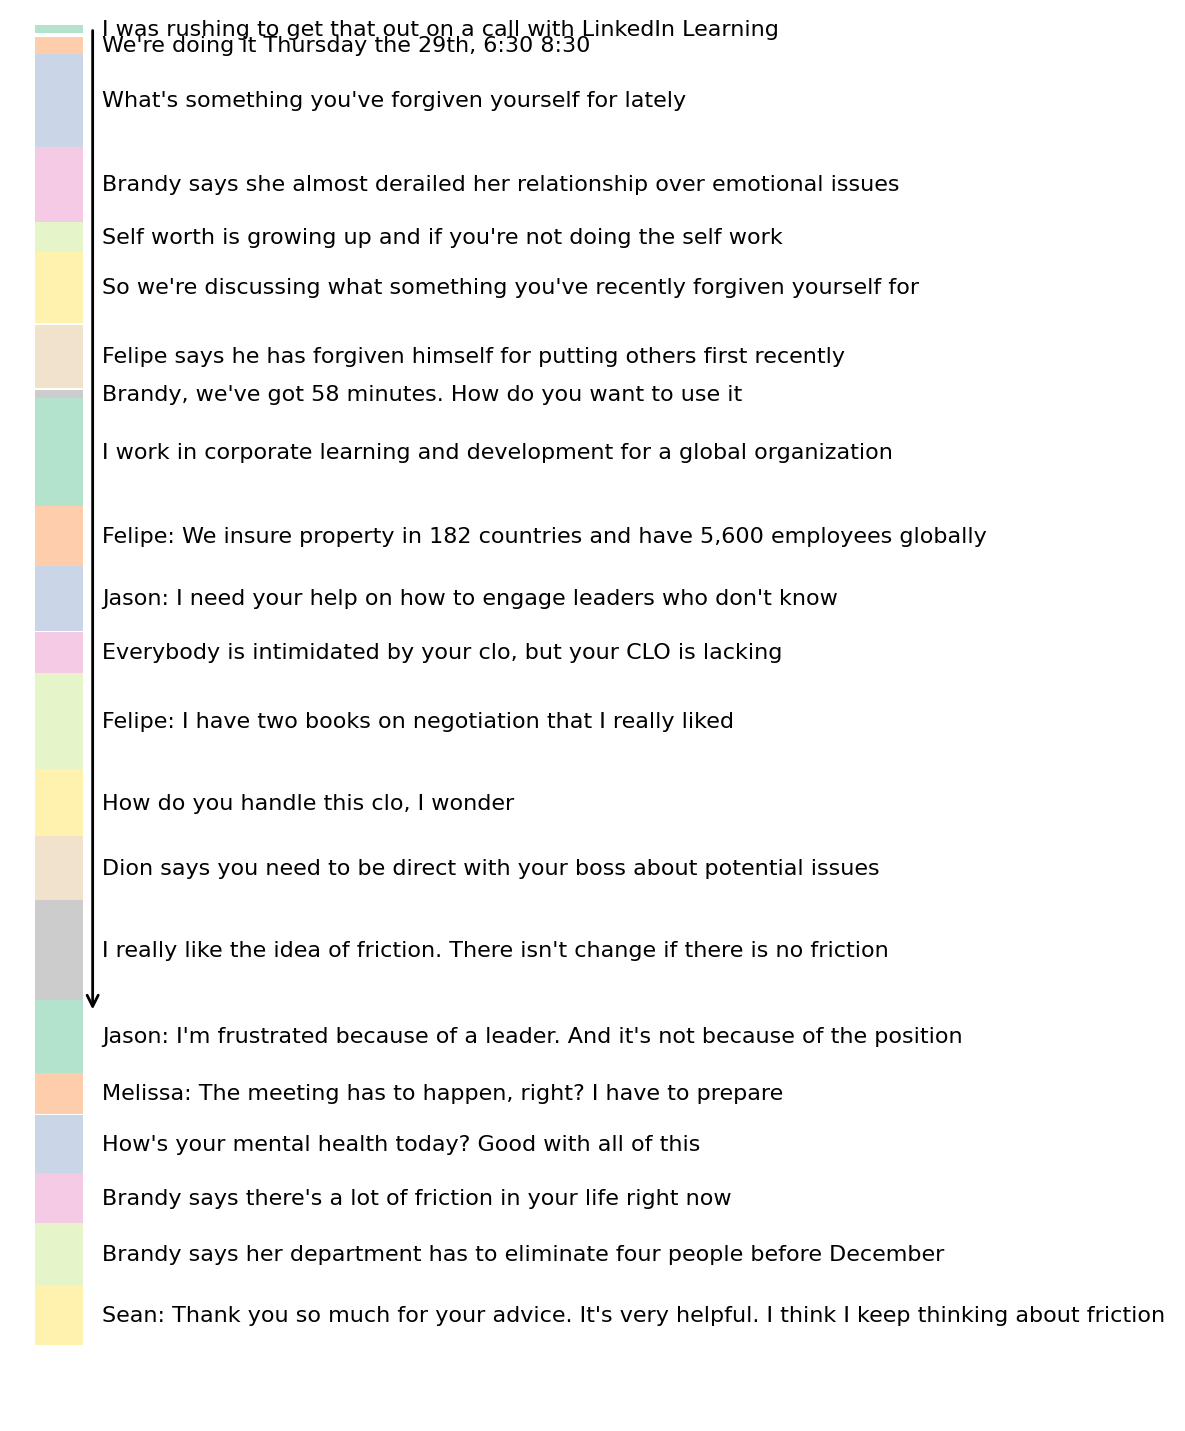

In [50]:
import numpy as np
import matplotlib.pyplot as plt

chap_times = np.ndarray(0)
texts = np.ndarray(0)

for chap in transcript['chapters']:
    # print(chap)
    start = chap['start']
    end = chap['end']
    duration = chap['end'] - chap['start']
    middle_point = int(start + duration / 2)
    # chap_times.append((start, end, end-start))
    chap_times = np.append(chap_times, (start, end, duration, middle_point))
    texts = np.append(texts, chap['headline'])

    # # Vertical bar
    # plt.text(0.5, -middle_point, chap['headline'])

# Unnecessary for plot, scale is computed automatically
# but transforms into seconds
chap_times = np.array(chap_times) / 1000

chap_times.shape = [len(transcript['chapters']), 4]
starts = chap_times[:, 0]
ends = chap_times[:, 1]
durations = chap_times[:, 2]
middle_points = chap_times[:, 3]

# See https://ultrapythonic.com/colormaps-in-matplotlib/
# colors = plt.get_cmap('tab20c').colors
# colors = plt.get_cmap('Pastel1').colors
colors = plt.get_cmap('Pastel2').colors
# colors = plt.get_cmap('Set3').colors

# Horizontal bar
# plt.figure(figsize=(10, 1))
# plt.ylim(-0.8, 0.8)
# plt.barh([0], durations, left=starts, height=1, color=colors)
# plt.annotate("", xytext=(0, 0.7), xy=(ends[-1]* (3/4), 0.7), arrowprops=dict(arrowstyle="->"))
# for mid, txt in zip(middle_points, texts):
#     plt.text(mid, 0.9, txt, size=8, rotation=45)

# # Vertical bar
plt.figure(figsize=(0.5, 9))
plt.xlim(-0.8, 0.8)
plt.bar([0], -durations, bottom=-starts, width=1, color=colors)
plt.annotate("", xytext=(0.7, 0), xy=(0.7, -ends[-1]* (3/4)), arrowprops=dict(arrowstyle="->"))
for mid, txt in zip(middle_points, texts):
    plt.text(0.9, -mid, txt, size=8, verticalalignment='center')

plt.axis('off');

## Find Errors and Propose corrections

In [51]:
speaker_map_name_id = {speaker_map[key]['name']: key for key in speaker_map.keys()}
# speaker_map_name_id

In [52]:
# from IPython.display import display, Markdown

# # print('summary_one_sentence word count:', len(summary_one_paragraph.split()))
# display(Markdown(speaker_map[speaker_map_name_id['Felipe']]['errors_corrections']))